In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
MunicipalLitigation = pd.read_csv('municipal_litigation_fy_2002_2025.csv')
LitigationFinances = pd.read_csv('municipal_litigation_finances_2000_2025.csv')

#display(MunicipalLitigation.head())
#pd.set_option('display.max_columns', None)
#display(LitigationFinances.head())

In [ ]:
#GATEWAY CITIES TO REFERENCE BACK TO
gateway_cities = [
    'Attleboro', 'Barnstable', 'Brockton', 'Chelsea', 'Chicopee',
    'Everett', 'Fall River', 'Fitchburg', 'Haverhill', 'Holyoke',
    'Lawrence', 'Leominster', 'Lowell', 'Lynn', 'Malden',
    'Methuen', 'New Bedford', 'Peabody', 'Pittsfield', 'Quincy',
    'Revere', 'Salem', 'Springfield', 'Taunton', 'Westfield', 'Worcester'
]

In [1]:
# Filter MunicipalLitigation to only show rows where the municipality is a defendant
defendant_only = MunicipalLitigation[MunicipalLitigation['cases_defendant'] > 0]

NameError: name 'MunicipalLitigation' is not defined

In [ ]:
# 1. Trends in Fiscal Year (FY) Litigation Data
print("=== TOP 10 TOWNS AS PLAINTIFFS ===")
top_plaintiffs = MunicipalLitigation.groupby('municipality')['cases_plaintiff'].sum().nlargest(10)
print(top_plaintiffs)
print("\n=== TOP 10 TOWNS AS DEFENDANTS ===")
top_defendants = MunicipalLitigation.groupby('municipality')['cases_defendant'].sum().nlargest(10)
print(top_defendants)

=== TOP 10 TOWNS AS PLAINTIFFS ===
municipality
Worcester      11909
Springfield    10362
Boston          6341
New Bedford     2856
Revere          1378
Plymouth        1190
Brockton        1151
Malden           842
Fitchburg        715
Holyoke          706
Name: cases_plaintiff, dtype: int64

=== TOP 10 TOWNS AS DEFENDANTS ===
municipality
Boston         4095
Springfield    1025
Worcester       843
Lowell          561
Cambridge       526
Fall River      448
Somerville      438
Malden          408
Barnstable      358
Quincy          355
Name: cases_defendant, dtype: int64


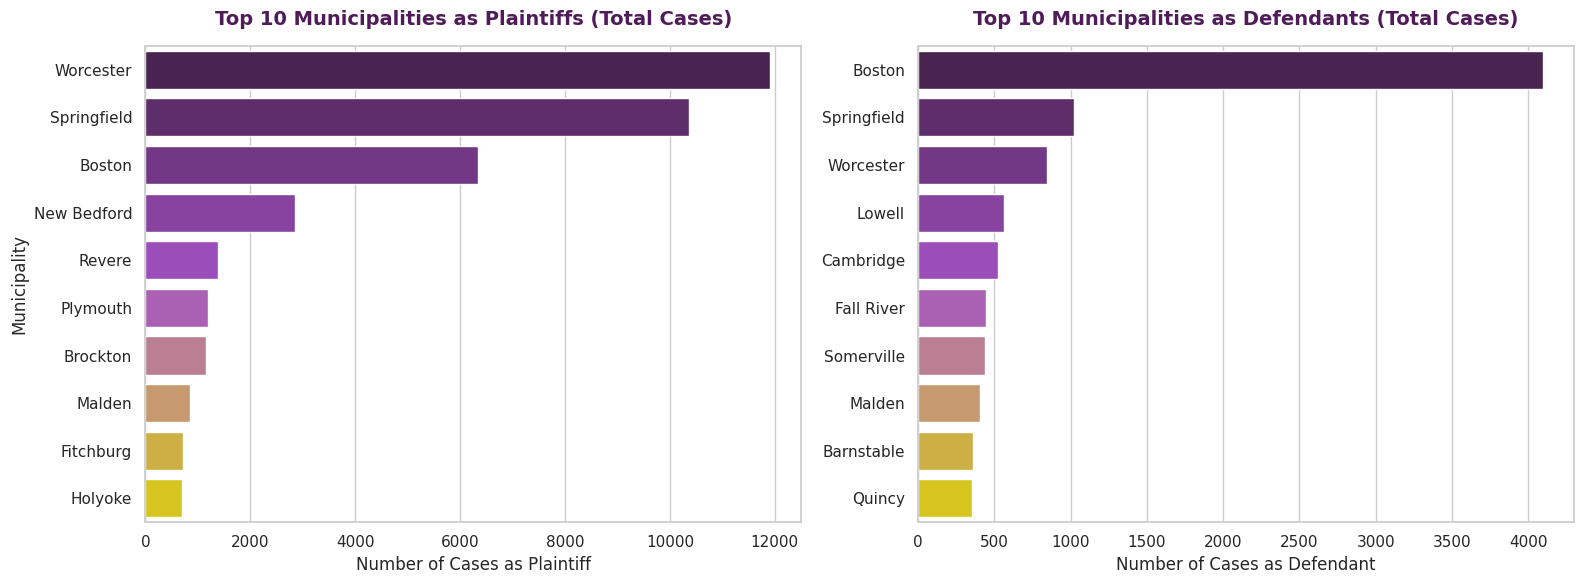

In [ ]:
# Set the style of the plots and define client colors
sns.set_theme(style="whitegrid")
from matplotlib.colors import LinearSegmentedColormap

brand_colors = {
    'purple': '#AD40D9',
    'dark_purple': '#4F1C59',
    'gray': '#9A9A9A',
    'yellow': '#F5DE00'
}

# Create a smooth custom gradient from dark purple -> purple -> yellow
custom_cmap = LinearSegmentedColormap.from_list("purple_yellow", [brand_colors['dark_purple'], brand_colors['purple'], brand_colors['yellow']])

# Generate 10-step color lists from the gradient
palette_steps = [custom_cmap(i / 9.0) for i in range(10)]

# Create a figure with two subplots side-by-side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot Top 10 Plaintiffs
sns.barplot(
    x=top_plaintiffs.values,
    y=top_plaintiffs.index,
    ax=axes[0],
    hue=top_plaintiffs.index,
    palette=palette_steps,
    legend=False
)
axes[0].set_title("Top 10 Municipalities as Plaintiffs (Total Cases)", fontsize=14, pad=15, color=brand_colors['dark_purple'], fontweight='bold')
axes[0].set_xlabel("Number of Cases as Plaintiff", fontsize=12)
axes[0].set_ylabel("Municipality", fontsize=12)

# Plot Top 10 Defendants
sns.barplot(
    x=top_defendants.values,
    y=top_defendants.index,
    ax=axes[1],
    hue=top_defendants.index,
    palette=palette_steps,
    legend=False
)
axes[1].set_title("Top 10 Municipalities as Defendants (Total Cases)", fontsize=14, pad=15, color=brand_colors['dark_purple'], fontweight='bold')
axes[1].set_xlabel("Number of Cases as Defendant", fontsize=12)
axes[1].set_ylabel("", fontsize=12)

plt.tight_layout()
plt.show()

=== LITIGATION ROLE RATIO COMPARISON ===


,is_gateway,cases_plaintiff,cases_defendant,Total Cases,Plaintiff %,Defendant %
0,Gateway Cities,35211,7570,42781,82.305229,17.694771
1,Other Municipalities,28431,18341,46772,60.786368,39.213632


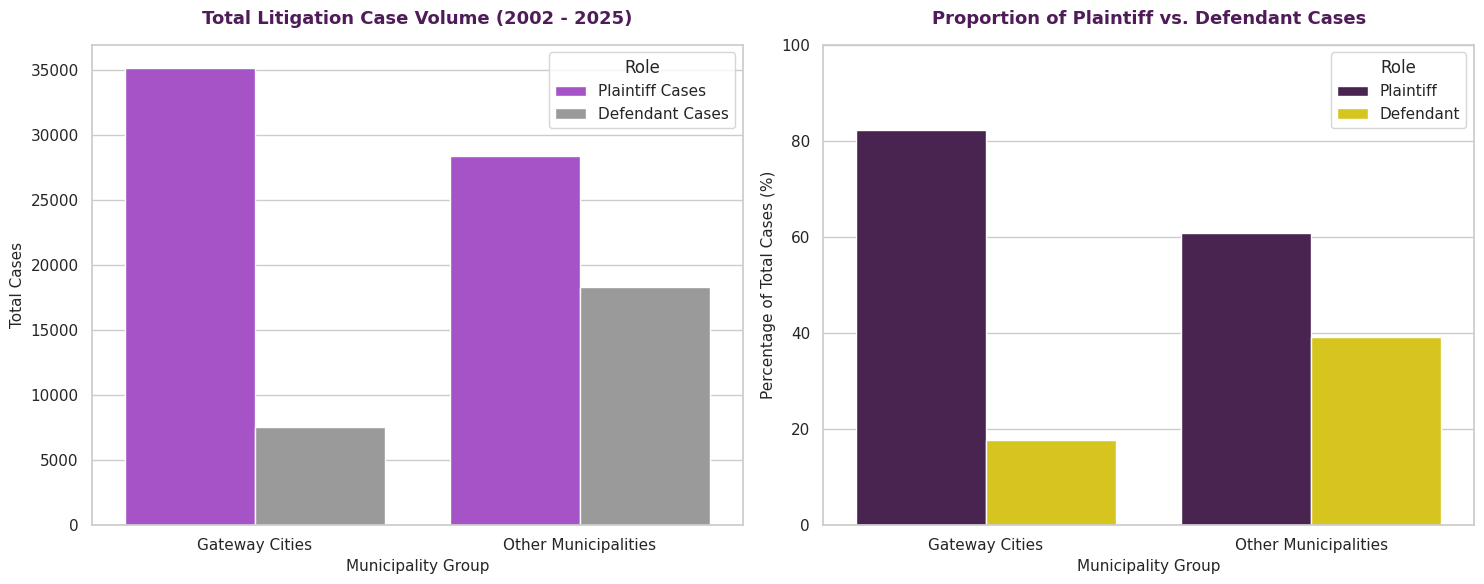

In [ ]:
# 6. Comparing Gateway Cities to Other Municipalities as Plaintiffs vs. Defendants
brand_colors = {'purple': '#AD40D9', 'dark_purple': '#4F1C59', 'gray': '#9A9A9A', 'yellow': '#F5DE00'}

# Classify municipalities into Gateway vs. Non-Gateway
MunicipalLitigation['is_gateway'] = MunicipalLitigation['municipality'].isin(gateway_cities).map({True: 'Gateway Cities', False: 'Other Municipalities'})

# Sum up cases for each category
litigation_comparison = MunicipalLitigation.groupby('is_gateway')[['cases_plaintiff', 'cases_defendant']].sum().reset_index()

# Reshape for easier plotting with seaborn
litigation_melted = litigation_comparison.melt(
    id_vars='is_gateway',
    value_vars=['cases_plaintiff', 'cases_defendant'],
    var_name='Role',
    value_name='Number of Cases'
)

# Clean up the names for display
litigation_melted['Role'] = litigation_melted['Role'].map({
    'cases_plaintiff': 'Plaintiff Cases',
    'cases_defendant': 'Defendant Cases'
})

# Calculate percentages to see proportions
total_by_group = litigation_comparison.copy()
total_by_group['Total Cases'] = total_by_group['cases_plaintiff'] + total_by_group['cases_defendant']
total_by_group['Plaintiff %'] = (total_by_group['cases_plaintiff'] / total_by_group['Total Cases']) * 100
total_by_group['Defendant %'] = (total_by_group['cases_defendant'] / total_by_group['Total Cases']) * 100

print("=== LITIGATION ROLE RATIO COMPARISON ===")
display(total_by_group)

# Plotting the comparison side-by-side
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Absolute Volume comparison
sns.barplot(
    data=litigation_melted,
    x='is_gateway',
    y='Number of Cases',
    hue='Role',
    ax=axes[0],
    palette=[brand_colors['purple'], brand_colors['gray']]
)
axes[0].set_title("Total Litigation Case Volume (2002 - 2025)", fontsize=13, pad=15, color=brand_colors['dark_purple'], fontweight='bold')
axes[0].set_xlabel("Municipality Group", fontsize=11)
axes[0].set_ylabel("Total Cases", fontsize=11)

# Proportional / Percentage comparison
proportions_df = total_by_group.melt(
    id_vars='is_gateway',
    value_vars=['Plaintiff %', 'Defendant %'],
    var_name='Role',
    value_name='Percentage of Cases'
)
proportions_df['Role'] = proportions_df['Role'].str.replace(' %', '')

sns.barplot(
    data=proportions_df,
    x='is_gateway',
    y='Percentage of Cases',
    hue='Role',
    ax=axes[1],
    palette=[brand_colors['dark_purple'], brand_colors['yellow']]
)
axes[1].set_title("Proportion of Plaintiff vs. Defendant Cases", fontsize=13, pad=15, color=brand_colors['dark_purple'], fontweight='bold')
axes[1].set_xlabel("Municipality Group", fontsize=11)
axes[1].set_ylabel("Percentage of Total Cases (%)", fontsize=11)
axes[1].set_ylim(0, 100)

plt.tight_layout()
plt.show()

=== INDIVIDUAL GATEWAY CITIES LITIGATION PROFILES (Sorted by Volume) ===


,municipality,cases_plaintiff,cases_defendant,Total Cases,Plaintiff %,Defendant %
25,Worcester,11909,843,12752,93.389272,6.610728
22,Springfield,10362,1025,11387,90.998507,9.001493
16,New Bedford,2856,326,3182,89.754871,10.245129
20,Revere,1378,236,1614,85.377943,14.622057
2,Brockton,1151,274,1425,80.771930,19.228070
14,Malden,842,408,1250,67.360000,32.640000
9,Holyoke,706,190,896,78.794643,21.205357
4,Chicopee,681,195,876,77.739726,22.260274
7,Fitchburg,715,152,867,82.468281,17.531719
13,Lynn,605,245,850,71.176471,28.823529


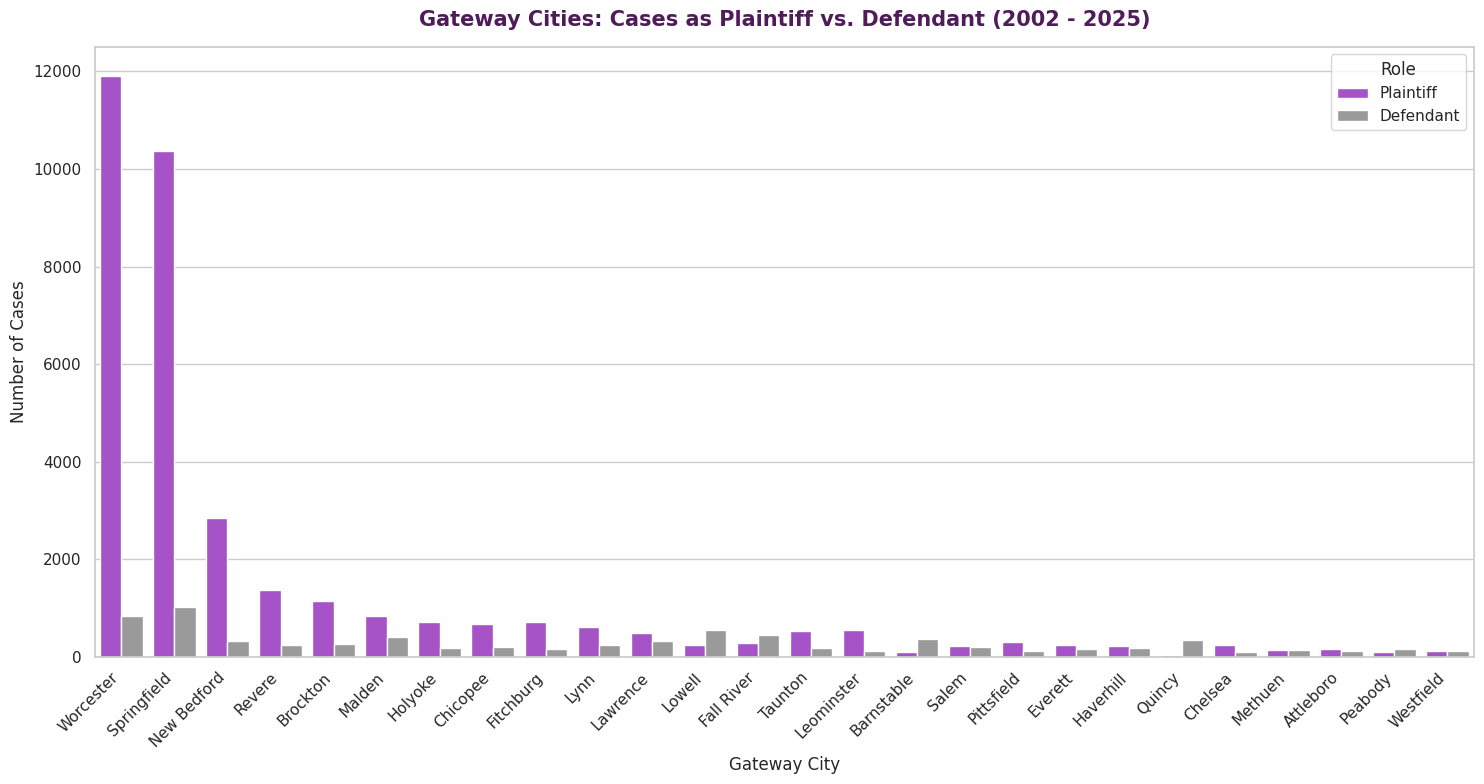

In [ ]:
# 7. Individual Gateway Cities Plaintiff vs. Defendant Comparison
brand_colors = {'purple': '#AD40D9', 'dark_purple': '#4F1C59', 'gray': '#9A9A9A', 'yellow': '#F5DE00'}

# Filter litigation data for Gateway Cities only
gateway_litigation = MunicipalLitigation[MunicipalLitigation['municipality'].isin(gateway_cities)]

# Group by individual municipality
city_comparison = gateway_litigation.groupby('municipality')[['cases_plaintiff', 'cases_defendant']].sum().reset_index()
city_comparison['Total Cases'] = city_comparison['cases_plaintiff'] + city_comparison['cases_defendant']
city_comparison['Plaintiff %'] = (city_comparison['cases_plaintiff'] / city_comparison['Total Cases']) * 100
city_comparison['Defendant %'] = (city_comparison['cases_defendant'] / city_comparison['Total Cases']) * 100

# Sort by total cases
city_comparison_sorted = city_comparison.sort_values(by='Total Cases', ascending=False)

print("=== INDIVIDUAL GATEWAY CITIES LITIGATION PROFILES (Sorted by Volume) ===")
display(city_comparison_sorted)

# Melt for plotting
city_melted = city_comparison_sorted.melt(
    id_vars='municipality',
    value_vars=['cases_plaintiff', 'cases_defendant'],
    var_name='Role',
    value_name='Number of Cases'
)
city_melted['Role'] = city_melted['Role'].map({
    'cases_plaintiff': 'Plaintiff',
    'cases_defendant': 'Defendant'
})

# Plotting individual profiles with brand colors
plt.figure(figsize=(15, 8))
sns.barplot(
    data=city_melted,
    x='municipality',
    y='Number of Cases',
    hue='Role',
    palette=[brand_colors['purple'], brand_colors['gray']]
)
plt.title("Gateway Cities: Cases as Plaintiff vs. Defendant (2002 - 2025)", fontsize=15, pad=15, color=brand_colors['dark_purple'], fontweight='bold')
plt.xlabel("Gateway City", fontsize=12)
plt.ylabel("Number of Cases", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
# 2. Category trends over the years
print("\n=== LITIGATION CATEGORY TRENDS OVER YEARS (SUM) ===")
category_cols = [
    'cases_tax_lien', 'cases_housing', 'cases_tort_defendant',
    'cases_admin_defendant', 'cases_procedural',
]
yearly_categories = MunicipalLitigation.groupby('fiscal_year')[category_cols].sum()
print(yearly_categories.tail(10))


=== LITIGATION CATEGORY TRENDS OVER YEARS (SUM) ===
             cases_tax_lien  cases_housing  cases_tort_defendant  \
fiscal_year                                                        
2016                   1592           1687                   107   
2017                   1792           1578                    95   
2018                   1545           1569                   112   
2019                   1489           1403                   102   
2020                   1103           1059                   100   
2021                   1160            817                   100   
2022                   1311            764                    80   
2023                   1013            637                    98   
2024                    740            604                    83   
2025                    544            597                   101   

             cases_admin_defendant  cases_procedural  
fiscal_year                                           
2016                

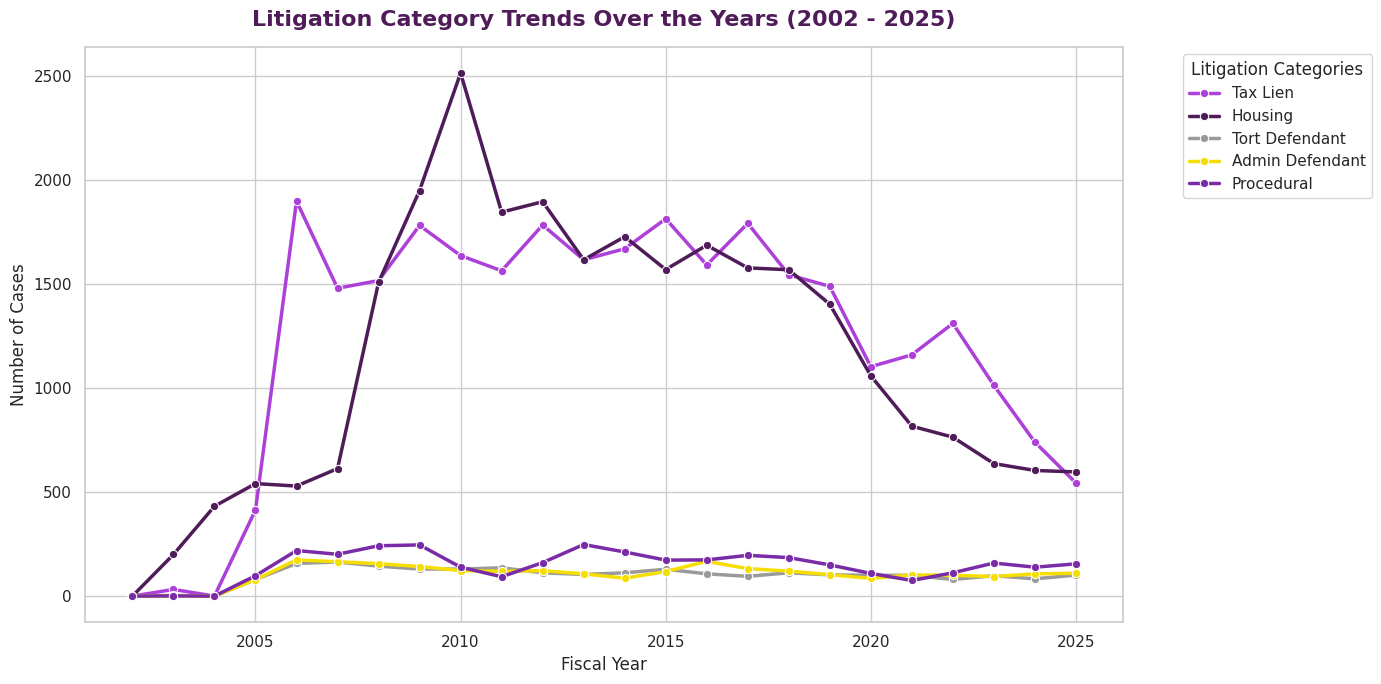

In [ ]:
# Set seaborn style and colors
sns.set_theme(style="whitegrid")
brand_colors = ['#AD40D9', '#4F1C59', '#9A9A9A', '#F5DE00', '#7A2CA8', '#C38FE6']

# Plot yearly trends for litigation categories
plt.figure(figsize=(14, 7))
for i, column in enumerate(category_cols):
    sns.lineplot(
        data=yearly_categories,
        x=yearly_categories.index,
        y=column,
        marker='o',
        linewidth=2.5,
        color=brand_colors[i % len(brand_colors)],
        label=column.replace('cases_', '').replace('_', ' ').title()
    )

plt.title("Litigation Category Trends Over the Years (2002 - 2025)", fontsize=16, pad=15, color='#4F1C59', fontweight='bold')
plt.xlabel("Fiscal Year", fontsize=12)
plt.ylabel("Number of Cases", fontsize=12)
plt.legend(title="Litigation Categories", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

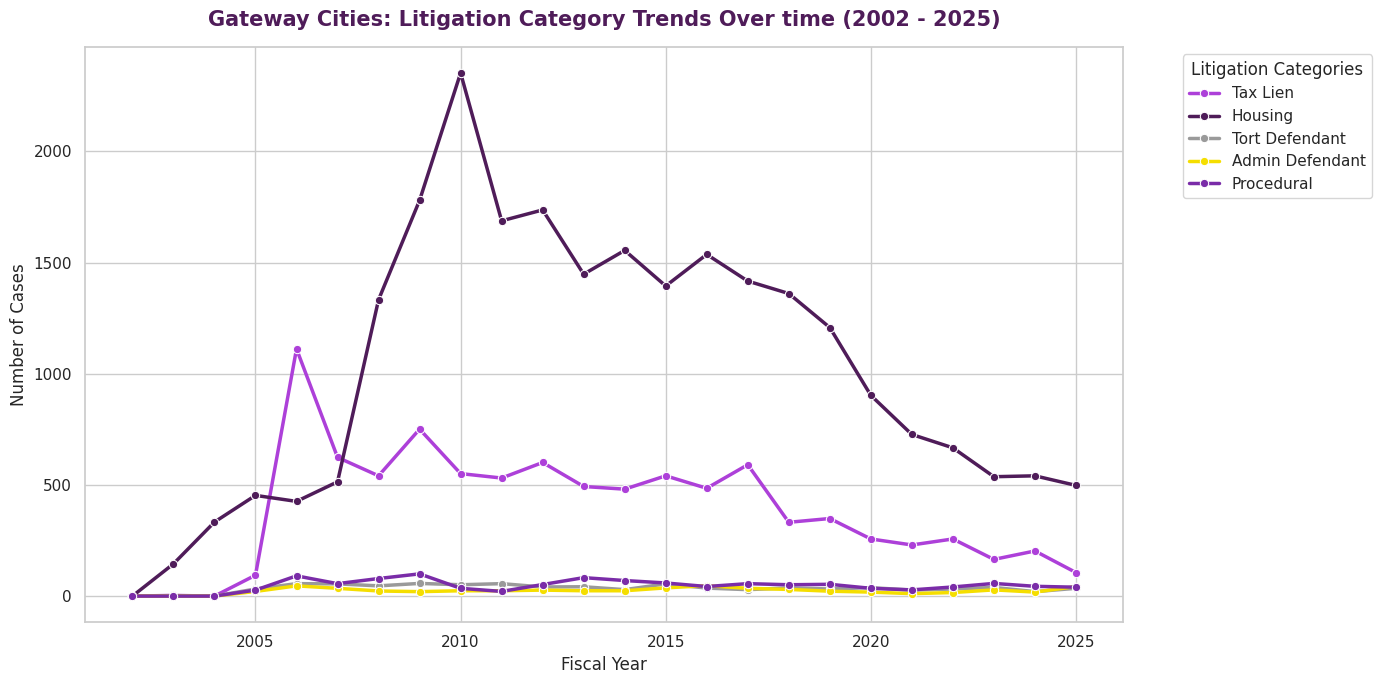

In [ ]:
# 8. Litigation Category Trends for the 26 Gateway Cities
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Filter the litigation data for Gateway Cities
gateway_litigation_data = MunicipalLitigation[MunicipalLitigation['municipality'].isin(gateway_cities)]

# Define the litigation category columns to analyze
category_cols = [
    'cases_tax_lien', 'cases_housing', 'cases_tort_defendant',
    'cases_admin_defendant', 'cases_procedural',
]

# Group by fiscal year
gateway_yearly_categories = gateway_litigation_data.groupby('fiscal_year')[category_cols].sum()

# Set colors
sns.set_theme(style="whitegrid")
brand_colors = ['#AD40D9', '#4F1C59', '#9A9A9A', '#F5DE00', '#7A2CA8', '#C38FE6']

# Plot yearly trends with brand colors
plt.figure(figsize=(14, 7))
for i, column in enumerate(category_cols):
    sns.lineplot(
        data=gateway_yearly_categories,
        x=gateway_yearly_categories.index,
        y=column,
        marker='o',
        linewidth=2.5,
        color=brand_colors[i % len(brand_colors)],
        label=column.replace('cases_', '').replace('_', ' ').title()
    )

plt.title("Gateway Cities: Litigation Category Trends Over time (2002 - 2025)", fontsize=15, pad=15, color='#4F1C59', fontweight='bold')
plt.xlabel("Fiscal Year", fontsize=12)
plt.ylabel("Number of Cases", fontsize=12)
plt.legend(title="Litigation Categories", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
# 3. Financial Spending trends by municipality and over time
# We will check columns related to spending or expenditures in LitigationFinances
spending_cols = [col for col in LitigationFinances.columns if 'spend' in col.lower() or 'expend' in col.lower() or 'cost' in col.lower()]
print("\nDetected spending/expenditure columns in finance dataset:", spending_cols)

if spending_cols:
    primary_spending = spending_cols[0]
    print(f"\n=== TOP 10 SPENDING MUNICIPALITIES (Based on {primary_spending}) ===")
    top_spending = LitigationFinances.groupby('municipality')[primary_spending].sum().nlargest(10)
    print(top_spending)

    print(f"\n=== SPENDING TRENDS OVER TIME (Based on {primary_spending}) ===")
    yearly_spending = LitigationFinances.groupby('year')[primary_spending].sum()
    print(yearly_spending.tail(10))
else:
    print("No explicit spending or expenditure columns were detected with the simple search. Let's look at overall averages.")


Detected spending/expenditure columns in finance dataset: ['expenditure_general_government', 'expenditure_public_safety', 'expenditure_education', 'expenditure_public_works', 'expenditure_human_services', 'expenditure_culture_and_recreation', 'expenditure_fixed_costs', 'expenditure_intergov_assessments', 'expenditure_other_expenditures', 'expenditure_debt_service', 'expenditure_total_expenditures']

=== TOP 10 SPENDING MUNICIPALITIES (Based on expenditure_general_government) ===
municipality
Boston         3.578624e+09
Cambridge      7.691790e+08
Springfield    5.984547e+08
Somerville     5.596868e+08
New Bedford    4.999754e+08
Worcester      4.058472e+08
Quincy         3.586161e+08
Newton         3.529023e+08
Lowell         3.283813e+08
Lexington      3.131863e+08
Name: expenditure_general_government, dtype: float64

=== SPENDING TRENDS OVER TIME (Based on expenditure_general_government) ===
year
2016    1.134506e+09
2017    1.181100e+09
2018    1.227106e+09
2019    1.325681e+09
202

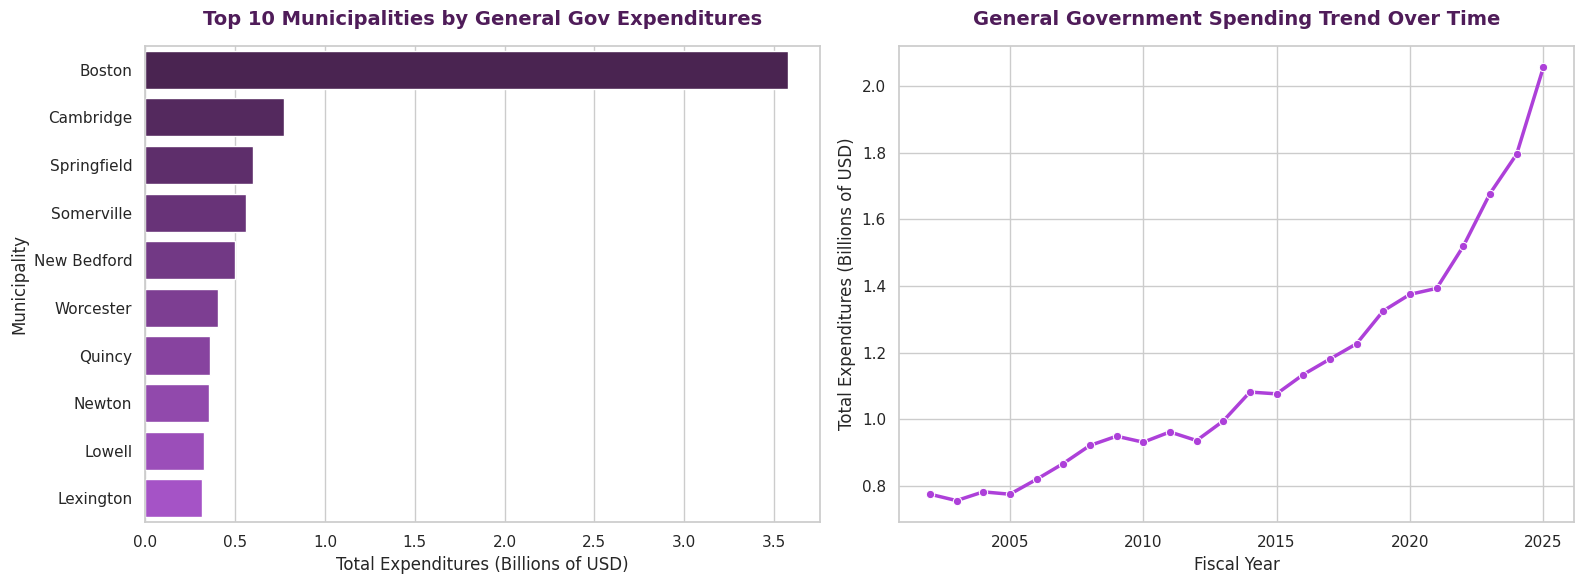

In [ ]:
# Set the styling theme
sns.set_theme(style="whitegrid")
from matplotlib.colors import LinearSegmentedColormap

brand_colors = {'purple': '#AD40D9', 'dark_purple': '#4F1C59', 'gray': '#9A9A9A', 'yellow': '#F5DE00'}

# Create a smooth purple gradient from dark purple to purple
purple_cmap = LinearSegmentedColormap.from_list("purple_spending_grad", [brand_colors['dark_purple'], brand_colors['purple']])
palette_spending = [purple_cmap(i / 9.0) for i in range(10)]

# Create side-by-side subplots for financial spending
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Top 10 Spending Municipalities
sns.barplot(
    x=top_spending.values / 1e9,
    y=top_spending.index,
    ax=axes[0],
    hue=top_spending.index,
    palette=palette_spending,
    legend=False
)
axes[0].set_title("Top 10 Municipalities by General Gov Expenditures", fontsize=14, pad=15, color=brand_colors['dark_purple'], fontweight='bold')
axes[0].set_xlabel("Total Expenditures (Billions of USD)", fontsize=12)
axes[0].set_ylabel("Municipality", fontsize=12)

# Plot 2: Spending Trends Over Time
valid_spending_trend = yearly_spending[yearly_spending > 0]
sns.lineplot(
    x=valid_spending_trend.index,
    y=valid_spending_trend.values / 1e9,
    ax=axes[1],
    marker='o',
    linewidth=2.5,
    color=brand_colors['purple']
)
axes[1].set_title("General Government Spending Trend Over Time", fontsize=14, pad=15, color=brand_colors['dark_purple'], fontweight='bold')
axes[1].set_xlabel("Fiscal Year", fontsize=12)
axes[1].set_ylabel("Total Expenditures (Billions of USD)", fontsize=12)

plt.tight_layout()
plt.show()

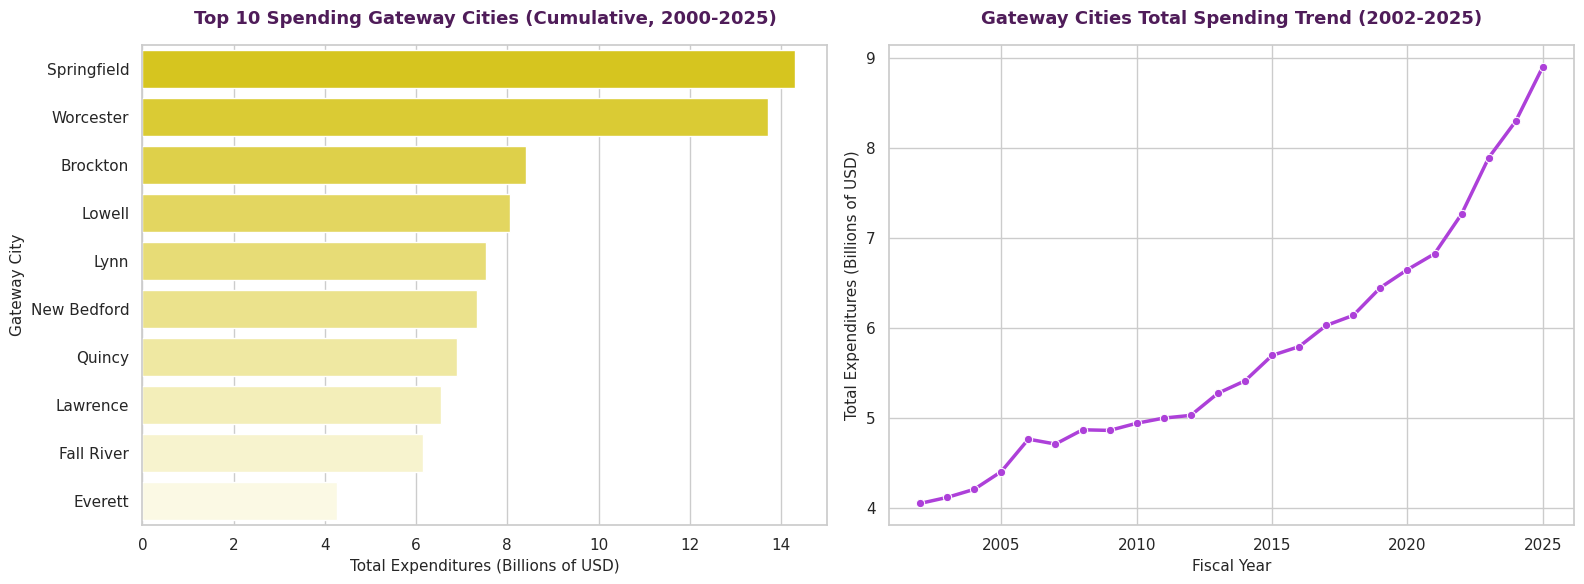

In [ ]:
# 5. Spending Municipalities and Trends for the 26 Gateway Cities
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# Ensure the dataset is loaded
try:
    _ = LitigationFinances.head()
except NameError:
    LitigationFinances = pd.read_csv('municipal_litigation_finances_2000_2025.csv')

brand_colors = {'purple': '#AD40D9', 'dark_purple': '#4F1C59', 'gray': '#9A9A9A', 'yellow': '#F5DE00'}

# Create a smooth yellow gradient from brand yellow to a light yellow
yellow_cmap = LinearSegmentedColormap.from_list("yellow_gradient", [brand_colors['yellow'], '#FFFCE0'])
palette_gateway_spending = [yellow_cmap(i / 9.0) for i in range(10)]

# Filter the finances dataset for Gateway Cities
gateway_finances = LitigationFinances[LitigationFinances['municipality'].isin(gateway_cities)]

# Group by municipality to find top total spenders (using total expenditures)
top_gateway_spending = gateway_finances.groupby('municipality')['expenditure_total_expenditures'].sum().nlargest(10)

# Group by year to check trends over time within Gateway Cities
gateway_yearly_spending = gateway_finances.groupby('year')['expenditure_total_expenditures'].sum()

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot Top 10 Gateway Spenders (Yellow Gradient)
sns.barplot(
    x=top_gateway_spending.values / 1e9,
    y=top_gateway_spending.index,
    ax=axes[0],
    hue=top_gateway_spending.index,
    palette=palette_gateway_spending,
    legend=False
)
axes[0].set_title("Top 10 Spending Gateway Cities (Cumulative, 2000-2025)", fontsize=13, pad=15, color=brand_colors['dark_purple'], fontweight='bold')
axes[0].set_xlabel("Total Expenditures (Billions of USD)", fontsize=11)
axes[0].set_ylabel("Gateway City", fontsize=11)

# Plot Overall Trend for Gateway Cities over time (2002 onwards) - Purple Line
valid_gateway_years = gateway_yearly_spending[gateway_yearly_spending.index >= 2002]
sns.lineplot(
    x=valid_gateway_years.index,
    y=valid_gateway_years.values / 1e9,
    ax=axes[1],
    marker='o',
    linewidth=2.5,
    color=brand_colors['purple']
)
axes[1].set_title("Gateway Cities Total Spending Trend (2002-2025)", fontsize=13, pad=15, color=brand_colors['dark_purple'], fontweight='bold')
axes[1].set_xlabel("Fiscal Year", fontsize=11)
axes[1].set_ylabel("Total Expenditures (Billions of USD)", fontsize=11)

plt.tight_layout()
plt.show()

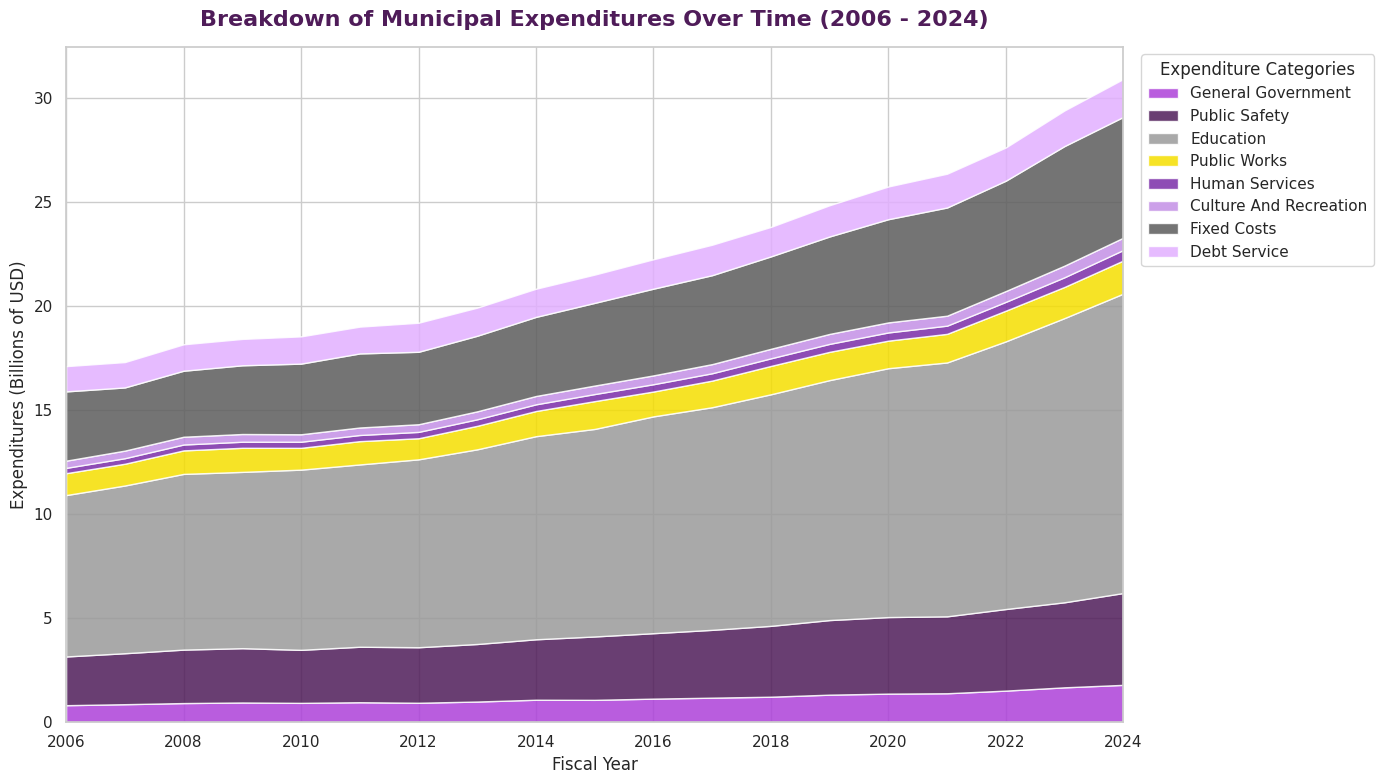

In [ ]:
# 4. Breakdown of Individual Expenditure Categories
brand_colors = ['#AD40D9', '#4F1C59', '#9A9A9A', '#F5DE00', '#7A2CA8', '#C38FE6', '#5C5C5C', '#E2AFFF']

# Exclude the total expenditures column to focus on individual categories
individual_expenditures = [
    'expenditure_general_government', 'expenditure_public_safety',
    'expenditure_education', 'expenditure_public_works',
    'expenditure_human_services', 'expenditure_culture_and_recreation',
    'expenditure_fixed_costs', 'expenditure_debt_service'
]

# Filter out columns actually present in the dataset
valid_cols = [col for col in individual_expenditures if col in LitigationFinances.columns]

# Aggregate yearly totals
yearly_breakdown = LitigationFinances.groupby('year')[valid_cols].sum()

# Filter the years to the range 2006 to 2024
yearly_breakdown = yearly_breakdown[(yearly_breakdown.index >= 2006) & (yearly_breakdown.index <= 2024)]

# Plot a stacked area chart matching client brand colors
plt.figure(figsize=(14, 8))
plt.stackplot(
    yearly_breakdown.index,
    [yearly_breakdown[col] / 1e9 for col in valid_cols],
    labels=[col.replace('expenditure_', '').replace('_', ' ').title() for col in valid_cols],
    colors=brand_colors[:len(valid_cols)],
    alpha=0.85
)

plt.title("Breakdown of Municipal Expenditures Over Time (2006 - 2024)", fontsize=16, pad=15, color='#4F1C59', fontweight='bold')
plt.xlabel("Fiscal Year", fontsize=12)
plt.ylabel("Expenditures (Billions of USD)", fontsize=12)
plt.xlim(2006, 2024)
plt.legend(title="Expenditure Categories", loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

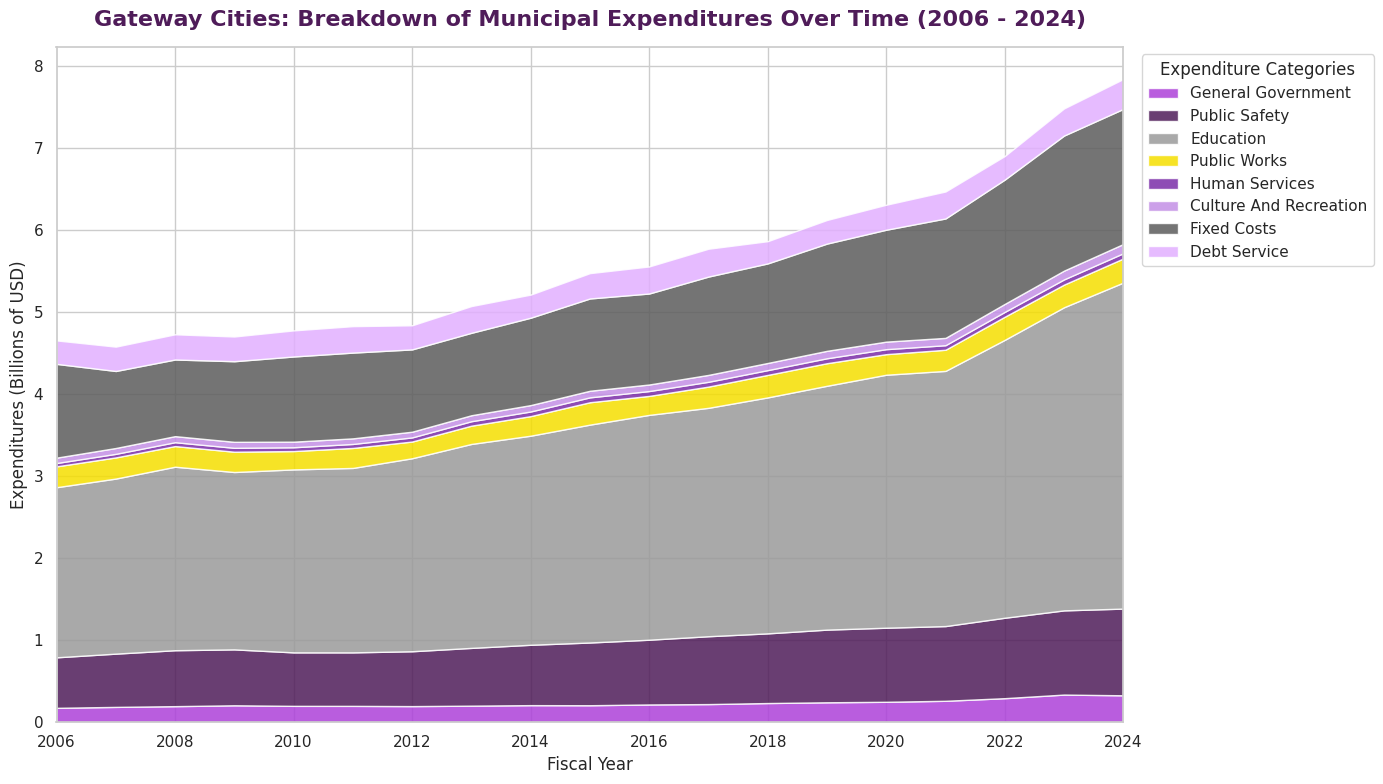

In [ ]:
# 4. Breakdown of Individual Expenditure Categories for Gateway Cities
brand_colors = ['#AD40D9', '#4F1C59', '#9A9A9A', '#F5DE00', '#7A2CA8', '#C38FE6', '#5C5C5C', '#E2AFFF']

# Filter finances dataset for only Gateway Cities
gateway_finances = LitigationFinances[LitigationFinances['municipality'].isin(gateway_cities)]

# Exclude the total expenditures column to focus on individual categories
individual_expenditures = [
    'expenditure_general_government', 'expenditure_public_safety',
    'expenditure_education', 'expenditure_public_works',
    'expenditure_human_services', 'expenditure_culture_and_recreation',
    'expenditure_fixed_costs', 'expenditure_debt_service'
]

# Filter out columns actually present in the dataset
valid_cols = [col for col in individual_expenditures if col in gateway_finances.columns]

# Aggregate yearly totals for Gateway Cities
gateway_yearly_breakdown = gateway_finances.groupby('year')[valid_cols].sum()

# Filter the years to the range 2006 to 2024
gateway_yearly_breakdown = gateway_yearly_breakdown[(gateway_yearly_breakdown.index >= 2006) & (gateway_yearly_breakdown.index <= 2024)]

# Plot a stacked area chart matching client brand colors
plt.figure(figsize=(14, 8))
plt.stackplot(
    gateway_yearly_breakdown.index,
    [gateway_yearly_breakdown[col] / 1e9 for col in valid_cols],
    labels=[col.replace('expenditure_', '').replace('_', ' ').title() for col in valid_cols],
    colors=brand_colors[:len(valid_cols)],
    alpha=0.85
)

plt.title("Gateway Cities: Breakdown of Municipal Expenditures Over Time (2006 - 2024)", fontsize=16, pad=15, color='#4F1C59', fontweight='bold')
plt.xlabel("Fiscal Year", fontsize=12)
plt.ylabel("Expenditures (Billions of USD)", fontsize=12)
plt.xlim(2006, 2024)
plt.legend(title="Expenditure Categories", loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()